# Footprint and service performance

Run this notebook to calculate results directly from `outputs/`. Figures go to the shared `figures/` folder. Original and alpha runs use 35 days; resampled runs use 70 days. Each Greenfilling run is compared with EASY for the same workload and trace.

Full-platform energy and footprint include idle nodes and context jobs. Service metrics exclude context jobs. With constant idle and busy power per node, footprint is

$$F(H)=NP_i\int_0^H I(t)dt+(P_b-P_i)\sum_j n_j\int_{s_j}^{s_j+r_j}I(t)dt.$$

Power times integrated intensity is divided by 3,600,000 to convert watt-seconds to kWh. These common-interval calculations retain the corrections to the original exports, whose energy and footprint used different intervals.

Mean bounded slowdown is the mean of $\max(R_j/\max(r_j,10),1)$. Work-weighted response time weights each response by executed node-seconds.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ANALYSIS = Path.cwd() if Path.cwd().name == "analysis" else Path.cwd() / "analysis"
sys.path.insert(0, str(ANALYSIS))
from helpers import experiments, platform, load_jobs, load_signals, performance, physical_totals

FIGURES = ANALYSIS / "figures"
FIGURES.mkdir(exist_ok=True)
horizons = {"original": 35 * 86400, "resampled": 70 * 86400, "alpha-sensitivity": 35 * 86400}

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.alpha": 0.22,
        "pdf.fonttype": 42,
        "savefig.dpi": 300,
    }
)
COLORS = {"carbon": "#2677ad", "water": "#b85d18"}
ORDER = ["mustang_slack", "mustang_stress", "trinity_slack", "trinity_stress"]
CLASSES = ["narrow-short", "other", "wide"]
CLASS_COLORS = ["#2677ad", "#a6acb1", "#b85d18"]
WORKLOAD_COLORS = dict(zip(ORDER, ["#2677ad", "#b85d18", "#568c43", "#7c5aa1"]))


def results_typography(fig):
    """Apply the bundled Roboto Condensed font to results figures only."""
    from matplotlib import font_manager
    from matplotlib.text import Text

    font_path = ANALYSIS / "fonts/RobotoCondensed-Regular.ttf"
    font_manager.fontManager.addfont(str(font_path))
    family = font_manager.FontProperties(fname=font_path).get_name()
    for text in fig.findobj(Text):
        text.set_fontfamily(family)
        text.set_fontsize(12)
    for ax in fig.axes:
        ax.xaxis.label.set_fontsize(14)
        ax.yaxis.label.set_fontsize(14)
        ax.title.set_fontsize(14)
    for legend in fig.legends:
        for text in legend.get_texts():
            text.set_fontsize(14)
    if fig._suptitle is not None:
        fig._suptitle.set_fontsize(16)

In [2]:
rows = []
for group, horizon in horizons.items():
    config = experiments(group)
    # Read each shared trace and platform once within this calculation.
    signals = {path: load_signals(path) for path in config.environmental_trace.unique()}
    platforms = {path: platform(path) for path in config.platform.unique()}
    for _, exp in config.iterrows():
        machine = platforms[exp.platform]
        jobs = load_jobs(group, exp["name"], machine["nodes"])
        rows.append(
            {
                key: exp[key]
                for key in ["group", "workload", "trace", "variant", "objective", "alpha"]
            }
            | performance(jobs)
            | physical_totals(jobs, machine, signals[exp.environmental_trace], horizon)
        )
    print(group, len(config), "runs")
runs = pd.DataFrame(rows)

original 432 runs


resampled 216 runs


alpha-sensitivity 168 runs


In [3]:
case = ["group", "workload", "trace"]
metrics = [
    "carbon_g",
    "water_l",
    "energy_kwh",
    "bounded_slowdown",
    "weighted_response_seconds",
    "median_wait_seconds",
    "p95_wait_seconds",
    "makespan_seconds",
]
easy = runs.loc[runs.variant == "easy_bf", case + metrics]
pairs = runs.loc[runs.variant != "easy_bf"].merge(easy, on=case, suffixes=("_green", "_easy"))
for metric in metrics:
    pairs[metric + "_delta"] = pairs[metric + "_green"] - pairs[metric + "_easy"]
    pairs[metric + "_delta_pct"] = 100 * (
        pairs[metric + "_green"] / pairs[metric + "_easy"].replace(0, np.nan) - 1
    )
pairs["target_delta_pct"] = np.where(
    pairs.objective == "carbon", pairs.carbon_g_delta_pct, pairs.water_l_delta_pct
)
summary = pairs.groupby(["group", "workload", "objective", "alpha"]).agg(
    comparisons=("trace", "size"),
    footprint_pct=("target_delta_pct", "median"),
    slowdown_pct=("bounded_slowdown_delta_pct", "median"),
    response_time_pct=("weighted_response_seconds_delta_pct", "median"),
)
display(summary.round(4))

comparisons  footprint_pct  \
group             workload       objective alpha                               
alpha-sensitivity mustang_slack  carbon    0.3              6        -0.0786   
                                           0.5              6        -0.0751   
                                           0.8              6        -0.0607   
                                 water     0.3              6        -0.0364   
                                           0.5              6        -0.0117   
                                           0.8              6        -0.0316   
                  mustang_stress carbon    0.3              6         0.0506   
                                           0.5              6         0.0225   
                                           0.8              6         0.0196   
                                 water     0.3              6         0.0340   
                                           0.5              6         0.0789   
                                           0.8              6         0.0855   
                  trinity_slack  carbon    0.3              6        -0.0056   
                                           0.5              6        -0.0053   
                                           0.8              6        -0.0069   
                                 water     0.3              6         0.0025   
                                           0.5              6        -0.0038   
                                           0.8              6        -0.0071   
                  trinity_stress carbon    0.3              6         0.0026   
                                           0.5              6         0.0026   
                                           0.8              6         0.0025   
                                 water     0.3              6         0.0007   
                                           0.5              6         0.0012   
                                           0.8              6         0.0012   
original          mustang_slack  carbon    0.5             36        -0.0676   
                                 water     0.5             36        -0.0307   
                  mustang_stress carbon    0.5             36         0.0077   
                                 water     0.5             36         0.0139   
                  trinity_slack  carbon    0.5             36        -0.0053   
                                 water     0.5             36        -0.0065   
                  trinity_stress carbon    0.5             36         0.0009   
                                 water     0.5             36        -0.0003   
resampled         mustang_slack  carbon    0.5             36        -0.1904   
                                 water     0.5             36        -0.0211   
                  mustang_stress carbon    0.5             36        -0.0860   
                                 water     0.5             36        -0.0767   

                                                  slowdown_pct  \
group             workload       objective alpha                 
alpha-sensitivity mustang_slack  carbon    0.3        317.0184   
                                           0.5        332.5194   
                                           0.8        283.3644   
                                 water     0.3        273.9809   
                                           0.5        241.0066   
                                           0.8        221.1836   
                  mustang_stress carbon    0.3        201.2034   
                                           0.5        192.6605   
                                           0.8        159.7107   
                                 water     0.3        167.3401   
                                           0.5        156.4760   
                                           0.8        135.8519   
                  trinity_slack  carbon    0.3        259.1895   
                   

## Original and resampled results

Negative footprint changes indicate savings. Boxes show Q1–Q3, the line is the median, and whiskers cover the range across 36 trace windows. These describe variation across windows, not confidence intervals. Each row retains its own EASY baseline and accounting horizon.

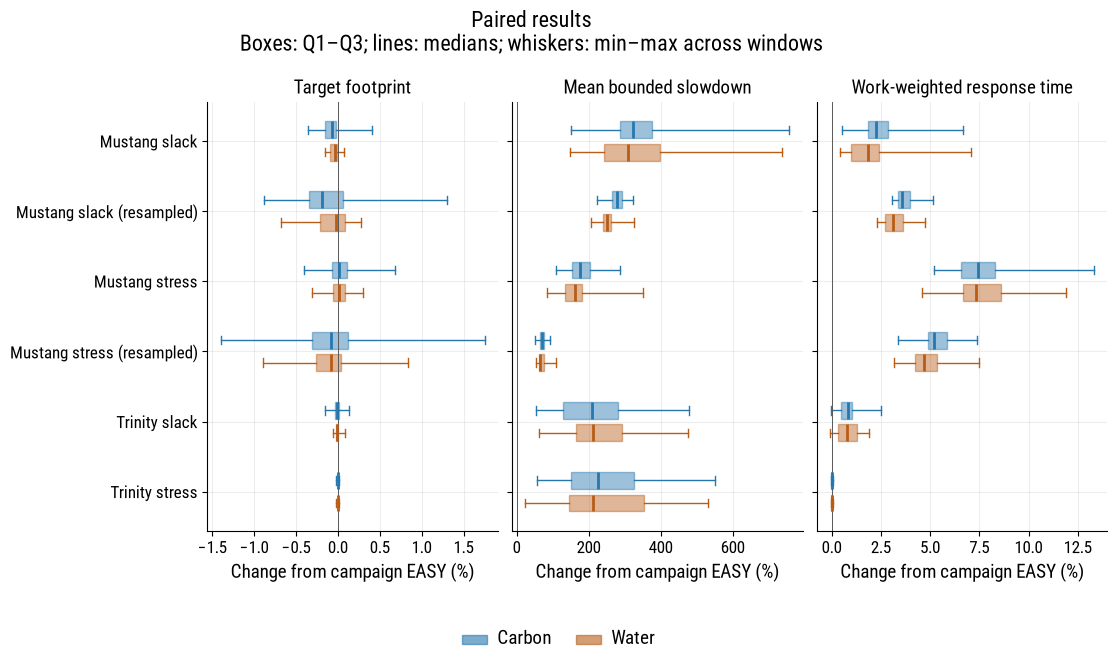

In [4]:
original_pairs = pairs.loc[pairs.group == "original"]
resampled_pairs = pairs.loc[pairs.group == "resampled"]
from matplotlib.patches import Patch

colors = {"carbon": "#2677ad", "water": "#b85d18"}
rows = [
    ("Mustang slack", original_pairs, "mustang_slack"),
    ("Mustang slack (resampled)", resampled_pairs, "mustang_slack"),
    ("Mustang stress", original_pairs, "mustang_stress"),
    ("Mustang stress (resampled)", resampled_pairs, "mustang_stress"),
    ("Trinity slack", original_pairs, "trinity_slack"),
    ("Trinity stress", original_pairs, "trinity_stress"),
]
metrics = [
    ("target_delta_pct", "Target footprint"),
    ("bounded_slowdown_delta_pct", "Mean bounded slowdown"),
    ("weighted_response_seconds_delta_pct", "Work-weighted response time"),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 6.6), sharey=True)
for ax, (metric, title) in zip(axes, metrics):
    for y, (_, row_pairs, workload) in enumerate(rows):
        for objective, offset in (("carbon", -0.16), ("water", 0.16)):
            values = row_pairs.loc[
                (row_pairs.workload == workload) & (row_pairs.objective == objective), metric
            ].to_numpy()
            color = colors[objective]
            ax.boxplot(
                values,
                positions=[y + offset],
                widths=0.24,
                orientation="horizontal",
                whis=(0, 100),
                showfliers=False,
                patch_artist=True,
                manage_ticks=False,
                boxprops={"facecolor": color, "edgecolor": color, "alpha": 0.45},
                medianprops={"color": color, "linewidth": 2},
                whiskerprops={"color": color},
                capprops={"color": color},
            )
    ax.axvline(0, color=".35", lw=0.7)
    ax.set_title(title)
    ax.set_xlabel("Change from campaign EASY (%)")
axes[0].set_yticks(range(len(rows)), [label for label, _, _ in rows])
axes[0].invert_yaxis()
fig.legend(
    handles=[
        Patch(facecolor=color, edgecolor=color, alpha=0.6, label=objective.capitalize())
        for objective, color in colors.items()
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
)
fig.subplots_adjust(left=0.23, right=0.98, top=0.84, bottom=0.19, wspace=0.05)
fig.suptitle(
    "Paired results\nBoxes: Q1–Q3; lines: medians; whiskers: min–max across windows", y=0.98
)
results_typography(fig)
for suffix in ("pdf", "png"):
    fig.savefig(FIGURES / ("paired_results" + "." + suffix), bbox_inches="tight")
plt.show()

## Smoothing-factor sensitivity

Four original workloads and six windows are run at α = 0.3, 0.5 and 0.8, with a fresh EASY baseline per case. For each country, the selected window is the middle start date among the available winter or summer windows. These are repeated settings of the same cases, not independent samples. The comparison below uses differences in percentage points relative to α = 0.5.

target_difference_vs_a050_pp  \
workload       objective alpha                                 
mustang_slack  carbon    0.3                          0.0136   
                         0.5                          0.0000   
                         0.8                          0.0140   
               water     0.3                          0.0008   
                         0.5                          0.0000   
                         0.8                         -0.0079   
mustang_stress carbon    0.3                         -0.0061   
                         0.5                          0.0000   
                         0.8                         -0.0066   
               water     0.3                          0.0190   
                         0.5                          0.0000   
                         0.8                          0.0135   
trinity_slack  carbon    0.3                         -0.0002   
                         0.5                          0.0000   
                         0.8                         -0.0000   
               water     0.3                         -0.0003   
                         0.5                          0.0000   
                         0.8                         -0.0000   
trinity_stress carbon    0.3                         -0.0000   
                         0.5                          0.0000   
                         0.8                          0.0000   
               water     0.3                         -0.0001   
                         0.5                          0.0000   
                         0.8                          0.0000   

                                bounded_slowdown_difference_vs_a050_pp  \
workload       objective alpha                                           
mustang_slack  carbon    0.3                                   15.4590   
                         0.5                                    0.0000   
                         0.8                                  -83.3097   
               water     0.3                                   19.3558   
                         0.5                                    0.0000   
                         0.8                                  -49.1099   
mustang_stress carbon    0.3                                   30.8450   
                         0.5                                    0.0000   
                         0.8                                  -26.7217   
               water     0.3                                   16.1762   
                         0.5                                    0.0000   
                         0.8                                  -27.2931   
trinity_slack  carbon    0.3                                   89.6566   
                         0.5                                    0.0000   
                         0.8                                  -14.2460   
               water     0.3                                   15.0904   
                         0.5                                    0.0000   
                         0.8                                  -58.3700   
trinity_stress carbon    0.3                                   38.4905   
                         0.5                                    0.0000   
                         0.8                                   -7.8077   
               water     0.3                                  132.2212   
                         0.5                                    0.0000   
                         0.8                                   -3.2496   

                                weighted_response_seconds_difference_vs_a050_pp  
workload       objective alpha                                                   
mustang_slack  carbon    0.3                                             0.0697  
                         0.5                                             0.0000  
                         0.8                                             0.0755  
               water     0.3    

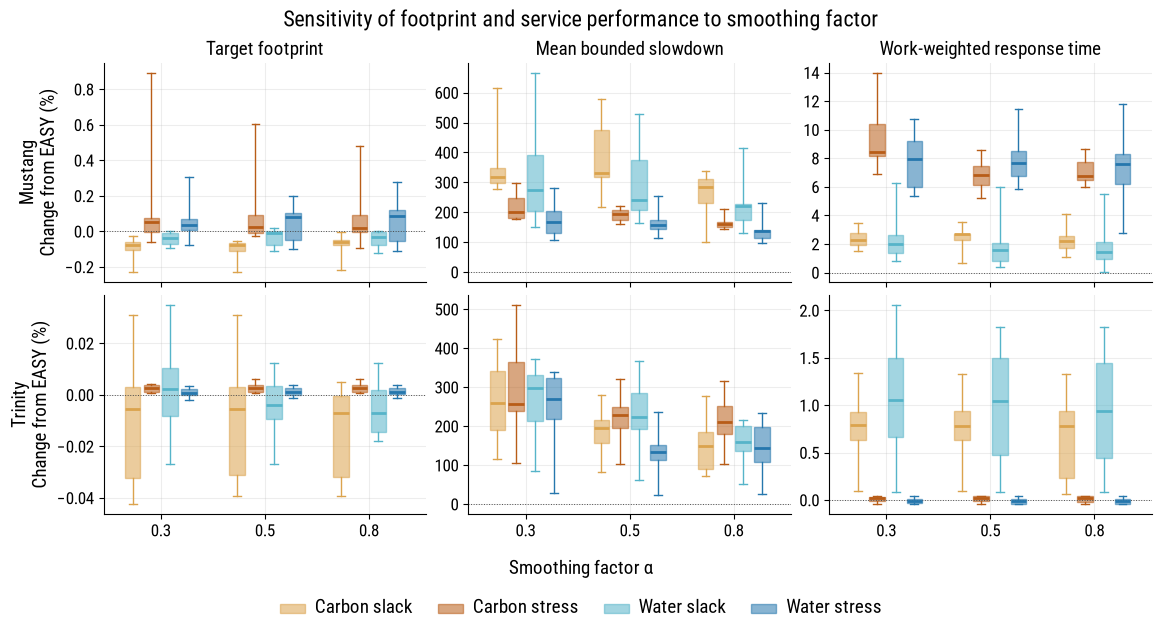

In [5]:
columns = ["target_delta_pct", "bounded_slowdown_delta_pct", "weighted_response_seconds_delta_pct"]
sensitivity = pairs.loc[pairs.group == "alpha-sensitivity"].copy()
case = ["workload", "trace", "objective"]
reference = sensitivity.loc[sensitivity.alpha == 0.5, case + columns]
sensitivity = sensitivity.merge(reference, on=case, suffixes=("", "_a050"))
for column in columns:
    sensitivity[column.replace("_delta_pct", "_difference_vs_a050_pp")] = (
        sensitivity[column] - sensitivity[column + "_a050"]
    )
sensitivity["competitive"] = (sensitivity.target_delta_pct < 0) & (
    sensitivity.bounded_slowdown_delta_pct <= 0
)
sensitivity["pareto_among_alphas_and_easy"] = False
for _, cases in sensitivity.groupby(case):
    values = cases[["target_delta_pct", "bounded_slowdown_delta_pct"]].to_numpy()
    alternatives = np.vstack([values, [0.0, 0.0]])
    for index, value in zip(cases.index, values):
        dominated = np.any(
            np.all(alternatives <= value, axis=1) & np.any(alternatives < value, axis=1)
        )
        sensitivity.loc[index, "pareto_among_alphas_and_easy"] = not dominated
display(
    sensitivity.groupby(["workload", "objective", "alpha"])[
        [c.replace("_delta_pct", "_difference_vs_a050_pp") for c in columns]
    ]
    .median()
    .round(4)
)

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

columns = ["target_delta_pct", "bounded_slowdown_delta_pct", "weighted_response_seconds_delta_pct"]
titles = ["Target footprint", "Mean bounded slowdown", "Work-weighted response time"]
fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.2), layout="constrained", sharex="col")
series = [(objective, load) for objective in ("carbon", "water") for load in ("slack", "stress")]
colors = {
    ("carbon", "slack"): "#dba34d",
    ("carbon", "stress"): "#b85d18",
    ("water", "slack"): "#56b4c9",
    ("water", "stress"): "#2677ad",
}
alphas = [0.3, 0.5, 0.8]
positions = np.arange(len(alphas))
offsets = np.array([-0.27, -0.09, 0.09, 0.27])
for row, machine_name in enumerate(("mustang", "trinity")):
    for column, (metric, title) in enumerate(zip(columns, titles)):
        ax = axes[row, column]
        for (objective, load), offset in zip(series, offsets):
            subset = sensitivity.loc[
                (sensitivity.objective == objective)
                & (sensitivity.workload == f"{machine_name}_{load}")
            ]
            values = [subset.loc[subset.alpha == alpha, metric].to_numpy() for alpha in alphas]
            color = colors[objective, load]
            ax.boxplot(
                values,
                positions=positions + offset,
                widths=0.15,
                whis=(0, 100),
                showfliers=False,
                patch_artist=True,
                manage_ticks=False,
                boxprops={"facecolor": color, "edgecolor": color, "alpha": 0.55},
                medianprops={"color": color, "linewidth": 2},
                whiskerprops={"color": color},
                capprops={"color": color},
            )
        ax.axhline(0, color=".3", lw=0.7, ls=":")
        ax.set_xticks(positions, [str(alpha) for alpha in alphas])
        ax.set_xlim(-0.55, len(alphas) - 0.45)
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        if row == 0:
            ax.set_title(title)
        if column == 0:
            ax.set_ylabel(machine_name.capitalize() + "\nChange from EASY (%)")
fig.legend(
    handles=[
        Patch(
            facecolor=colors[objective, load],
            edgecolor=colors[objective, load],
            alpha=0.55,
            label=f"{objective.capitalize()} {load}",
        )
        for objective, load in series
    ],
    loc="lower center",
    ncol=4,
    frameon=False,
)
fig.set_layout_engine("constrained", rect=(0, 0.13, 1, 0.87))
shared_xlabel = fig.supxlabel("Smoothing factor α", y=0.075)
fig.suptitle("Sensitivity of footprint and service performance to smoothing factor")
results_typography(fig)
shared_xlabel.set_fontsize(14)
for suffix in ("pdf", "png"):
    fig.savefig(FIGURES / ("alpha_sensitivity_combined" + "." + suffix), bbox_inches="tight")
plt.show()